In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

In [16]:
DATA_PATH = Path("../raw/ibtracs.ALL.list.v04r01.csv")

df = pd.read_csv(DATA_PATH, skiprows=[1], low_memory=False)

print("Dataset loaded successfully!")
print("Shape:", df.shape)
df.head()

Dataset loaded successfully!
Shape: (729694, 174)


,SID,SEASON,NUMBER,BASIN,SUBBASIN,NAME,ISO_TIME,NATURE,LAT,LON,...,BOM_GUST_PER,REUNION_GUST,REUNION_GUST_PER,USA_SEAHGT,USA_SEARAD_NE,USA_SEARAD_SE,USA_SEARAD_SW,USA_SEARAD_NW,STORM_SPEED,STORM_DIR
0,1842298N11080,1842,1,NI,BB,UNNAMED,1842-10-25 03:00:00,NR,10.9,80.3,...,,,,,,,,,9,265
1,1842298N11080,1842,1,NI,BB,UNNAMED,1842-10-25 06:00:00,NR,10.9,79.8,...,,,,,,,,,9,265
2,1842298N11080,1842,1,NI,BB,UNNAMED,1842-10-25 09:00:00,NR,10.8,79.4,...,,,,,,,,,9,265
3,1842298N11080,1842,1,NI,BB,UNNAMED,1842-10-25 12:00:00,NR,10.8,78.9,...,,,,,,,,,9,265
4,1842298N11080,1842,1,NI,BB,UNNAMED,1842-10-25 15:00:00,NR,10.8,78.4,...,,,,,,,,,9,270


In [17]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

df.info()

Number of rows: 729694
Number of columns: 174

Column names:
['SID', 'SEASON', 'NUMBER', 'BASIN', 'SUBBASIN', 'NAME', 'ISO_TIME', 'NATURE', 'LAT', 'LON', 'WMO_WIND', 'WMO_PRES', 'WMO_AGENCY', 'TRACK_TYPE', 'DIST2LAND', 'LANDFALL', 'IFLAG', 'USA_AGENCY', 'USA_ATCF_ID', 'USA_LAT', 'USA_LON', 'USA_RECORD', 'USA_STATUS', 'USA_WIND', 'USA_PRES', 'USA_SSHS', 'USA_R34_NE', 'USA_R34_SE', 'USA_R34_SW', 'USA_R34_NW', 'USA_R50_NE', 'USA_R50_SE', 'USA_R50_SW', 'USA_R50_NW', 'USA_R64_NE', 'USA_R64_SE', 'USA_R64_SW', 'USA_R64_NW', 'USA_POCI', 'USA_ROCI', 'USA_RMW', 'USA_EYE', 'TOKYO_LAT', 'TOKYO_LON', 'TOKYO_GRADE', 'TOKYO_WIND', 'TOKYO_PRES', 'TOKYO_R50_DIR', 'TOKYO_R50_LONG', 'TOKYO_R50_SHORT', 'TOKYO_R30_DIR', 'TOKYO_R30_LONG', 'TOKYO_R30_SHORT', 'TOKYO_LAND', 'CMA_LAT', 'CMA_LON', 'CMA_CAT', 'CMA_WIND', 'CMA_PRES', 'HKO_LAT', 'HKO_LON', 'HKO_CAT', 'HKO_WIND', 'HKO_PRES', 'KMA_LAT', 'KMA_LON', 'KMA_CAT', 'KMA_WIND', 'KMA_PRES', 'KMA_R50_DIR', 'KMA_R50_LONG', 'KMA_R50_SHORT', 'KMA_R30_DIR', 'KMA_R

In [18]:
columns = [
    "SID", "NAME", "ISO_TIME", "LAT", "LON",
    "WMO_WIND", "WMO_PRES", "USA_WIND", "USA_SSHS"
]

available_columns = [col for col in columns if col in df.columns]

cyclone_df = df[available_columns].copy()

cyclone_df.head()

,SID,NAME,ISO_TIME,LAT,LON,WMO_WIND,WMO_PRES,USA_WIND,USA_SSHS
0,1842298N11080,UNNAMED,1842-10-25 03:00:00,10.9,80.3,,,,-5
1,1842298N11080,UNNAMED,1842-10-25 06:00:00,10.9,79.8,,,,-5
2,1842298N11080,UNNAMED,1842-10-25 09:00:00,10.8,79.4,,,,-5
3,1842298N11080,UNNAMED,1842-10-25 12:00:00,10.8,78.9,,,,-5
4,1842298N11080,UNNAMED,1842-10-25 15:00:00,10.8,78.4,,,,-5


In [19]:
for col in ["LAT", "LON", "WMO_WIND", "WMO_PRES", "USA_WIND", "USA_SSHS"]:
    if col in cyclone_df.columns:
        cyclone_df[col] = pd.to_numeric(
            cyclone_df[col], errors="coerce"
        )

cyclone_df["ISO_TIME"] = pd.to_datetime(
    cyclone_df["ISO_TIME"], errors="coerce"
)

print(cyclone_df.dtypes)

SID                    str
NAME                   str
ISO_TIME    datetime64[us]
LAT                float64
LON                float64
WMO_WIND           float64
WMO_PRES           float64
USA_WIND           float64
USA_SSHS             int64
dtype: object


Missing values per column:
SID              0
NAME             0
ISO_TIME         0
LAT              0
LON              0
WMO_WIND    559378
WMO_PRES    555701
USA_WIND    324482
USA_SSHS         0
dtype: int64


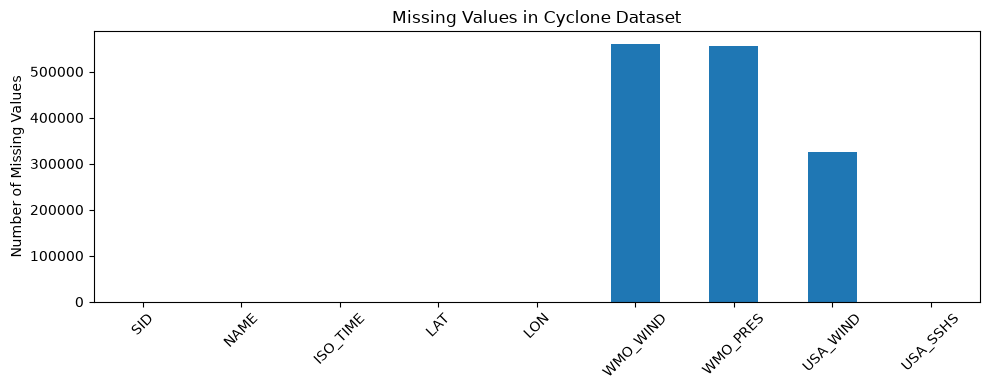

In [20]:
missing = cyclone_df.isnull().sum()

print("Missing values per column:")
print(missing)

missing.plot(kind="bar", figsize=(10, 4))
plt.title("Missing Values in Cyclone Dataset")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [21]:
north_indian = df[df["BASIN"] == "NI"].copy()

print("North Indian Ocean records:", len(north_indian))
print("Unique storms:", north_indian["SID"].nunique())

north_indian.head()

North Indian Ocean records: 57853
Unique storms: 1859


,SID,SEASON,NUMBER,BASIN,SUBBASIN,NAME,ISO_TIME,NATURE,LAT,LON,...,BOM_GUST_PER,REUNION_GUST,REUNION_GUST_PER,USA_SEAHGT,USA_SEARAD_NE,USA_SEARAD_SE,USA_SEARAD_SW,USA_SEARAD_NW,STORM_SPEED,STORM_DIR
0,1842298N11080,1842,1,NI,BB,UNNAMED,1842-10-25 03:00:00,NR,10.9,80.3,...,,,,,,,,,9,265
1,1842298N11080,1842,1,NI,BB,UNNAMED,1842-10-25 06:00:00,NR,10.9,79.8,...,,,,,,,,,9,265
2,1842298N11080,1842,1,NI,BB,UNNAMED,1842-10-25 09:00:00,NR,10.8,79.4,...,,,,,,,,,9,265
3,1842298N11080,1842,1,NI,BB,UNNAMED,1842-10-25 12:00:00,NR,10.8,78.9,...,,,,,,,,,9,265
4,1842298N11080,1842,1,NI,BB,UNNAMED,1842-10-25 15:00:00,NR,10.8,78.4,...,,,,,,,,,9,270


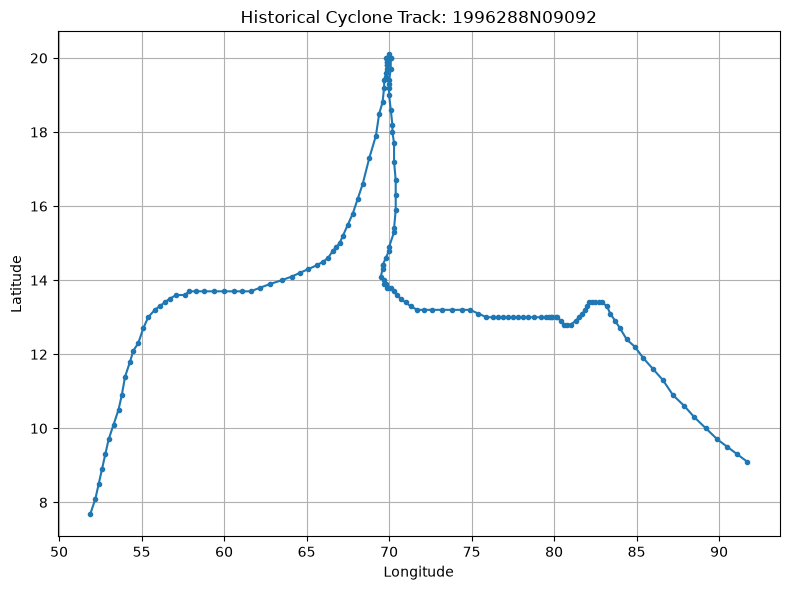

In [22]:
north_indian["LAT"] = pd.to_numeric(
    north_indian["LAT"], errors="coerce"
)
north_indian["LON"] = pd.to_numeric(
    north_indian["LON"], errors="coerce"
)

north_indian["ISO_TIME"] = pd.to_datetime(
    north_indian["ISO_TIME"], errors="coerce"
)

storm_counts = north_indian.groupby("SID")["LAT"].count()
storm_counts = storm_counts[storm_counts > 1]

if not storm_counts.empty:
    storm_id = storm_counts.idxmax()
    storm = north_indian[north_indian["SID"] == storm_id].copy()
    storm = storm.sort_values("ISO_TIME")
    storm = storm.dropna(subset=["LAT", "LON"])

    plt.figure(figsize=(8, 6))
    plt.plot(storm["LON"], storm["LAT"], marker="o", markersize=3)
    plt.xlabel("Longitude")
    plt.ylabel("Latitude")
    plt.title(f"Historical Cyclone Track: {storm_id}")
    plt.grid(True)
    plt.tight_layout()
    plt.show()
else:
    print("No suitable storm track found.")

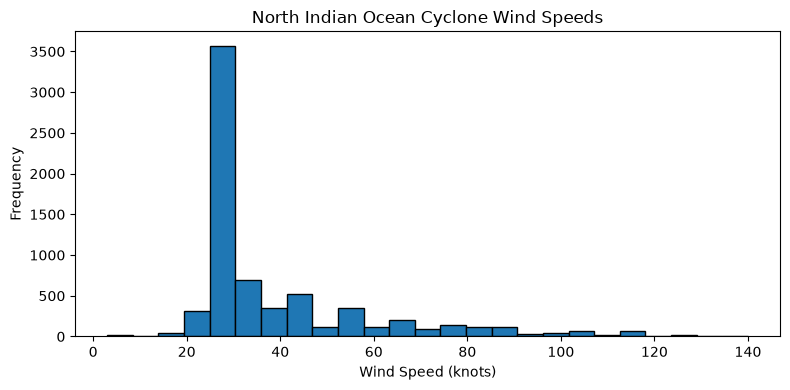

In [23]:
wind_col = "WMO_WIND"

if wind_col in north_indian.columns:
    wind = pd.to_numeric(north_indian[wind_col], errors="coerce")
    wind = wind.dropna()

    plt.figure(figsize=(8, 4))
    plt.hist(wind, bins=25, edgecolor="black")
    plt.xlabel("Wind Speed (knots)")
    plt.ylabel("Frequency")
    plt.title("North Indian Ocean Cyclone Wind Speeds")
    plt.tight_layout()
    plt.show()

In [24]:
OUTPUT_PATH = Path("../processed/north_indian_cyclones.csv")
OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)

north_indian.to_csv(OUTPUT_PATH, index=False)

In [25]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

df.info()

Number of rows: 729694
Number of columns: 174

Column names:
['SID', 'SEASON', 'NUMBER', 'BASIN', 'SUBBASIN', 'NAME', 'ISO_TIME', 'NATURE', 'LAT', 'LON', 'WMO_WIND', 'WMO_PRES', 'WMO_AGENCY', 'TRACK_TYPE', 'DIST2LAND', 'LANDFALL', 'IFLAG', 'USA_AGENCY', 'USA_ATCF_ID', 'USA_LAT', 'USA_LON', 'USA_RECORD', 'USA_STATUS', 'USA_WIND', 'USA_PRES', 'USA_SSHS', 'USA_R34_NE', 'USA_R34_SE', 'USA_R34_SW', 'USA_R34_NW', 'USA_R50_NE', 'USA_R50_SE', 'USA_R50_SW', 'USA_R50_NW', 'USA_R64_NE', 'USA_R64_SE', 'USA_R64_SW', 'USA_R64_NW', 'USA_POCI', 'USA_ROCI', 'USA_RMW', 'USA_EYE', 'TOKYO_LAT', 'TOKYO_LON', 'TOKYO_GRADE', 'TOKYO_WIND', 'TOKYO_PRES', 'TOKYO_R50_DIR', 'TOKYO_R50_LONG', 'TOKYO_R50_SHORT', 'TOKYO_R30_DIR', 'TOKYO_R30_LONG', 'TOKYO_R30_SHORT', 'TOKYO_LAND', 'CMA_LAT', 'CMA_LON', 'CMA_CAT', 'CMA_WIND', 'CMA_PRES', 'HKO_LAT', 'HKO_LON', 'HKO_CAT', 'HKO_WIND', 'HKO_PRES', 'KMA_LAT', 'KMA_LON', 'KMA_CAT', 'KMA_WIND', 'KMA_PRES', 'KMA_R50_DIR', 'KMA_R50_LONG', 'KMA_R50_SHORT', 'KMA_R30_DIR', 'KMA_R

In [26]:
columns = [
    "SID", "NAME", "ISO_TIME", "LAT", "LON",
    "WMO_WIND", "WMO_PRES", "USA_WIND", "USA_SSHS"
]

available_columns = [col for col in columns if col in df.columns]

cyclone_df = df[available_columns].copy()

cyclone_df.head()

,SID,NAME,ISO_TIME,LAT,LON,WMO_WIND,WMO_PRES,USA_WIND,USA_SSHS
0,1842298N11080,UNNAMED,1842-10-25 03:00:00,10.9,80.3,,,,-5
1,1842298N11080,UNNAMED,1842-10-25 06:00:00,10.9,79.8,,,,-5
2,1842298N11080,UNNAMED,1842-10-25 09:00:00,10.8,79.4,,,,-5
3,1842298N11080,UNNAMED,1842-10-25 12:00:00,10.8,78.9,,,,-5
4,1842298N11080,UNNAMED,1842-10-25 15:00:00,10.8,78.4,,,,-5


In [27]:
numeric_columns = [
    "LAT", "LON", "WMO_WIND",
    "WMO_PRES", "USA_WIND", "USA_SSHS"
]

for col in numeric_columns:
    if col in cyclone_df.columns:
        cyclone_df[col] = pd.to_numeric(
            cyclone_df[col], errors="coerce"
        )

cyclone_df["ISO_TIME"] = pd.to_datetime(
    cyclone_df["ISO_TIME"], errors="coerce"
)

print(cyclone_df.dtypes)

SID                    str
NAME                   str
ISO_TIME    datetime64[us]
LAT                float64
LON                float64
WMO_WIND           float64
WMO_PRES           float64
USA_WIND           float64
USA_SSHS             int64
dtype: object


In [ ]:
missing_values = cyclone_df.isnull().sum()

print("Missing values in each column:")
print(missing_values)

missing_percentage = (
    cyclone_df.isnull().sum() / len(cyclone_df) * 100
).round(2)

print("\nMissing percentage:")
print(missing_percentage)

In [ ]:
missing_values[missing_values > 0].plot(
    kind="bar",
    figsize=(10, 4)
)

plt.title("Missing Values in Cyclone Dataset")
plt.xlabel("Columns")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
north_indian = df[df["BASIN"].astype(str).str.strip() == "NI"].copy()

print("North Indian Ocean records:", len(north_indian))
print("Unique storms:", north_indian["SID"].nunique())

north_indian.head()

In [ ]:
north_indian["LAT"] = pd.to_numeric(
    north_indian["LAT"], errors="coerce"
)

north_indian["LON"] = pd.to_numeric(
    north_indian["LON"], errors="coerce"
)

north_indian["ISO_TIME"] = pd.to_datetime(
    north_indian["ISO_TIME"], errors="coerce"
)

storm_counts = (
    north_indian.dropna(subset=["LAT", "LON"])
    .groupby("SID")
    .size()
)

storm_counts = storm_counts[storm_counts > 1]

if not storm_counts.empty:
    storm_id = storm_counts.idxmax()

    storm = north_indian[
        north_indian["SID"] == storm_id
    ].sort_values("ISO_TIME")

    storm = storm.dropna(subset=["LAT", "LON"])

    plt.figure(figsize=(8, 6))
    plt.plot(storm["LON"], storm["LAT"], marker="o", markersize=3)
    plt.xlabel("Longitude")
    plt.ylabel("Latitude")
    plt.title(f"Historical Cyclone Track: {storm_id}")
    plt.grid(True)
    plt.tight_layout()
    plt.show()
else:
    print("No suitable cyclone track found.")